# The paper's figures

Every figure meant for the papers, drawn from this repository's code and the campaign's stored results. What a figure
*shows* -- which couplings are excluded, read from the plane summaries -- is computed by `analysis/exclusion.py`, which
is tested (`tests/test_exclusion.py`); how it *looks* is set here, so that a figure can be tuned in this notebook while
what it shows stays in tested code. The style is Mauricio's `matplotlibrc` (`analysis/matplotlibrc`, loaded by
`analysis.figure_style.use()`); text goes through LaTeX.

Running the whole notebook rewrites every figure in `paper/figures/` (PDF for the paper, PNG to look at):

    jupyter nbconvert --to notebook --execute --inplace notebooks/paper_figures.ipynb

**Inputs.** The plane summaries of the campaign of 2026-10-20 (`analysis/configs/campaign_ml/`: mixing fixed at the
centre of Table II, the lightest mass profiled exactly, the relic neutrinos thermal in every collision), computed on
Tycho and copied to `output/analysis/campaign_ml/<data set>/<plane>/<data|asimov>/plane_m_Zd_eV_g_D.json`, with the
refinement records beside them (`refine_*.jsonl`). They are not under version control; the inventory cell below
stops if one is missing. The data sets:

| key | in the legend | what it is |
|---|---|---|
| `now_ic26` | Today: IC MESE 11.4 yr flavor + spectrum | IceCube's MESE flavor composition (2025) and its 2026 spectrum |
| `now_events` | Today: IC HESE 7.5 yr + DR2 11.6 yr | HESE starting events, and IceTracks-DR2's IC79 + IC86 through-going tracks |
| `proj_future` | Projected: combined detectors | Asimov data for the 8 future detectors, 10 yr each, no new physics |

Each plane comes twice: with the sources' flavor composition fixed to pion decay ($f_{e,\rm S} = 1/3$) and with it
fitted (`_fx`; the extragalactic and the Galactic composition each free).

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
from analysis import exclusion as ex
from analysis.figure_style import DATASETS, PANEL, pct, ticks, tint, use

use()
#: The plane summaries.
CAMPAIGN = os.path.join(REPO, "output", "analysis", "campaign_ml")
#: Where the figures go.
FIGURE_DIR = os.path.join(REPO, "paper", "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)
#: The source-composition treatments: the planes' suffix, and how the legend names it.
COMPOSITIONS = {"pion": ("", r"fixing $f_{e,{\rm S}} = 1/3$"), "fitted": ("_fx", r"fitting $f_{e,{\rm S}}$")}
#: The regions are drawn largest first, so that the smaller ones sit on top (the fills are opaque).
DRAWN = DATASETS[::-1]
X_LABEL = r"Mediator mass, $\log_{10}(M'/{\rm eV})$"


def legend_title(composition):
    return f"Disfavored (95{pct()} C.L.), " + COMPOSITIONS[composition][1]


def handles():
    return [Patch(facecolor=tint(c), edgecolor=c, lw=1.5, label=label) for _, label, c in DATASETS]


def model_label(ax, text, size=22, where="top"):
    """The model's name in a rounded box, top left (or bottom left, where the regions fill the top)."""
    y, va = (0.94, "top") if where == "top" else (0.05, "bottom")
    ax.text(0.015, y, text, transform=ax.transAxes, ha="left", va=va, fontsize=size,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="0.25", lw=1.2))


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGURE_DIR, f"{name}.{ext}"))
    print("saved paper/figures/" + name + ".pdf")

## How a limit is read

Each plane is a grid of fits: at every (mediator mass, coupling) the $\chi^2$ is minimized over every other parameter.
A coupling is **disfavoured at 95% C.L.** when, at its mass, $\Delta\chi^2 = \chi^2 - \min_{\rm column}\chi^2 \geq
3.84$ (decided 2026-10-13: the planes are read per mass). On top of that, `analysis/exclusion.py` applies the rules
below (its docstring has the details):

- **Upper limits only.** Couplings below a column's lowest allowed one are never shaded. Where the data prefer an
  effect at some coupling, the no-effect couplings below it can sit above 3.84; they are disfavoured relative to that
  preference, not excluded.
- **Specks.** Isolated excluded grid regions of at most three points, none above $\Delta\chi^2 = 5$, are not shaded:
  a hair over 3.84, they come and go with the sampling.
- **Edges.** The 95% crossing is interpolated between samples at each mass, and neighbouring masses' crossings are
  joined by straight lines. Contouring $\Delta\chi^2$ itself would draw a staircase, because it jumps from ~0 to
  hundreds within one coupling step.
- **Thin bands.** With the compositions fitted, the ultralight planes also exclude a band ~0.5 decade wide along the
  edge of the pion-decay region. It exists only because each source's composition is taken to be the same at every
  energy, so it is left out here; the notes describe it ('Thin excluded bands with fitted source compositions').
- **Joined planes.** Each $L_\alpha - L_\beta$ model was scanned in two planes, ultralight ($10^{-30}$ to $10^4$ eV)
  and MeV ($10^4$ to $10^9$ eV). They agree where they meet, and are drawn as one region, so no seam shows.

Before these figures, six ultralight points at 10 keV whose fits had stuck in the wrong basin of the lightest neutrino
mass were refitted (`tools/refit_stuck_ml.py`, 2026-10-21); the summaries read here include them.

In [2]:
# The inventory: every plane the figures read, and its number of points.
MODELS = ["le_lmu_ul", "le_lmu_mev", "le_ltau_ul", "le_ltau_mev", "dp_e_mev", "dp_mu_mev", "dp_tau_mev"]
missing = []
for ds, label, _ in DATASETS:
    row = []
    for model in MODELS:
        for suffix, _ in COMPOSITIONS.values():
            path = ex.plane(CAMPAIGN, ds, model + suffix)
            if not path:
                missing.append(f"{ds}/{model + suffix}")
                continue
            import json
            s = json.load(open(path))
            row.append(sum(v is not None for r in s["chi2"] for v in r))
    print(f"{ds:12s} {len(row)} planes, {min(row)}-{max(row)} points each")
if missing:
    raise FileNotFoundError("missing plane summaries: " + ", ".join(missing))

now_ic26     14 planes, 1681-2135 points each
now_events   14 planes, 1681-2135 points each
proj_future  14 planes, 1681-2135 points each


## 1. $L_e - L_\mu$ and $L_e - L_\tau$, from $10^{-30}$ to $10^9$ eV

One wide panel per model, ultralight and MeV planes joined. The inset enlarges the MeV corner, $10^{2.5}$ to
$10^{7.5}$ eV and couplings $10^{-5}$ to $10^{-2}$, where the resonant absorption on relic neutrinos shapes the regions.
The panels share the mass axis, labelled under the lower one, and one coupling label. The legend sits in the upper
panel with its bottom on the inset's bottom (`borderaxespad=0`); the figure is 17.5 in wide so that the legend's
one-line title clears the $L_e - L_\mu$ regions with pion-decay sources (it does from $10^{-13.4}$ eV on).

Two versions: the sources' composition fixed to pion decay, and fitted.

saved paper/figures/limits_le_lmu_le_ltau_pion.pdf


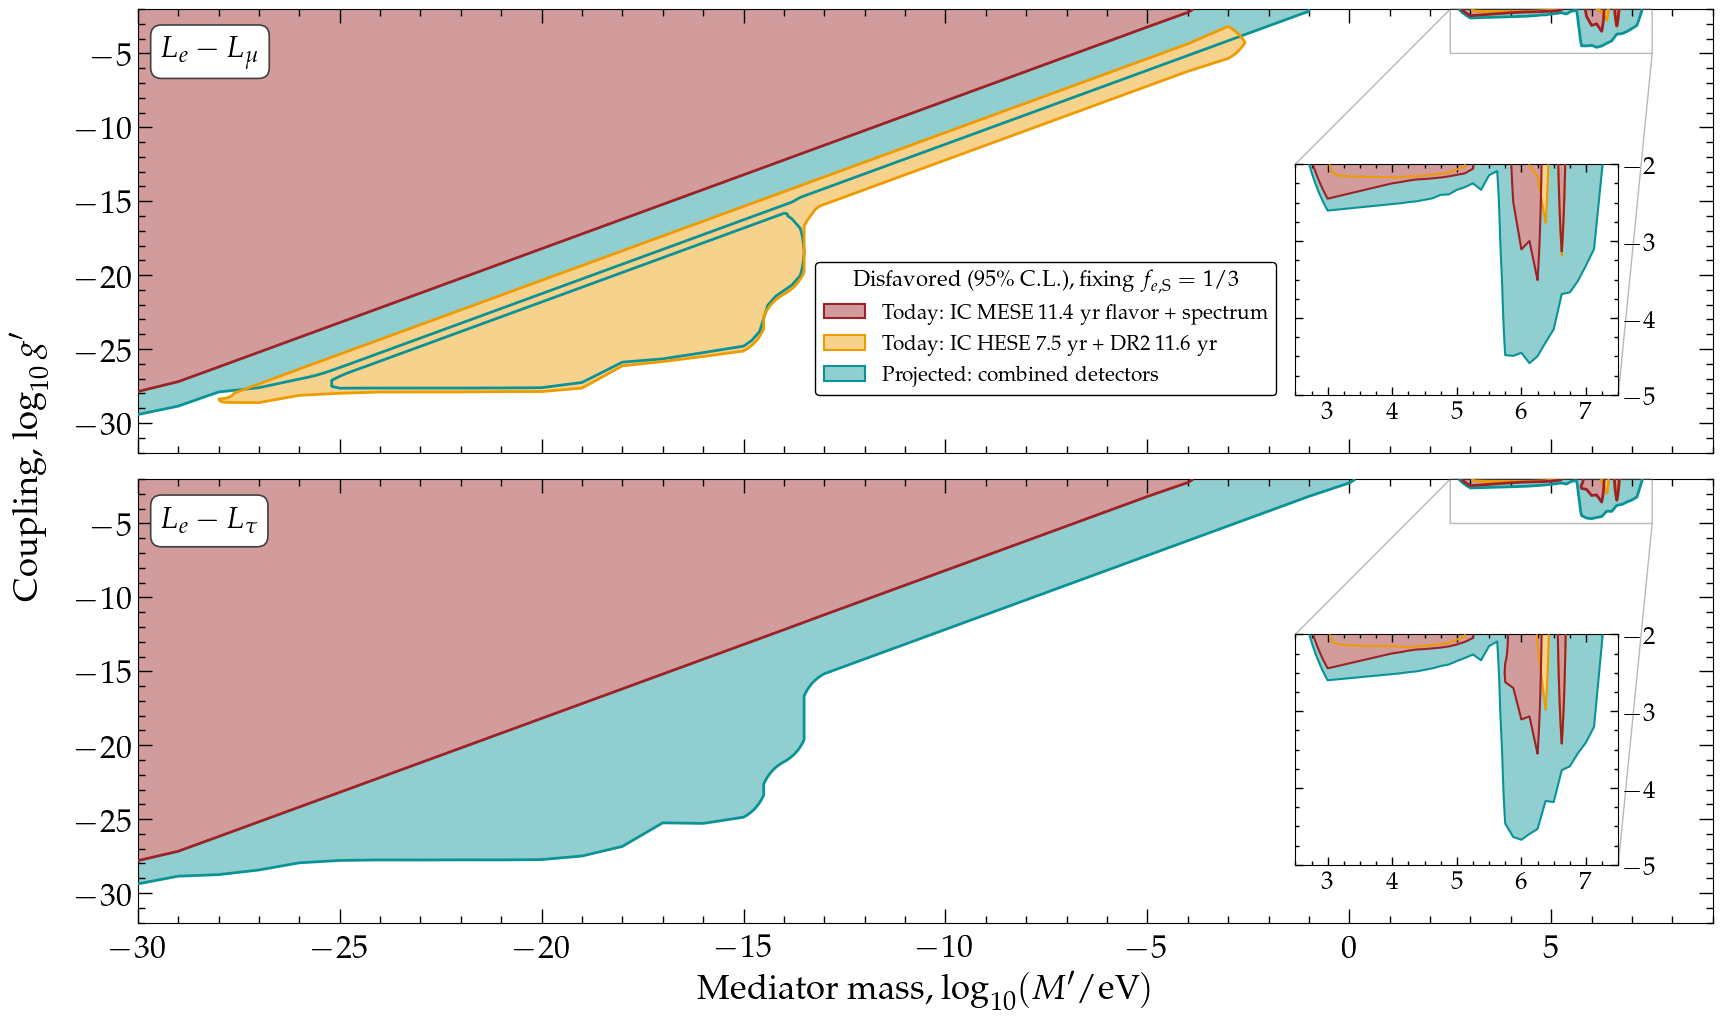

saved paper/figures/limits_le_lmu_le_ltau_fitted.pdf


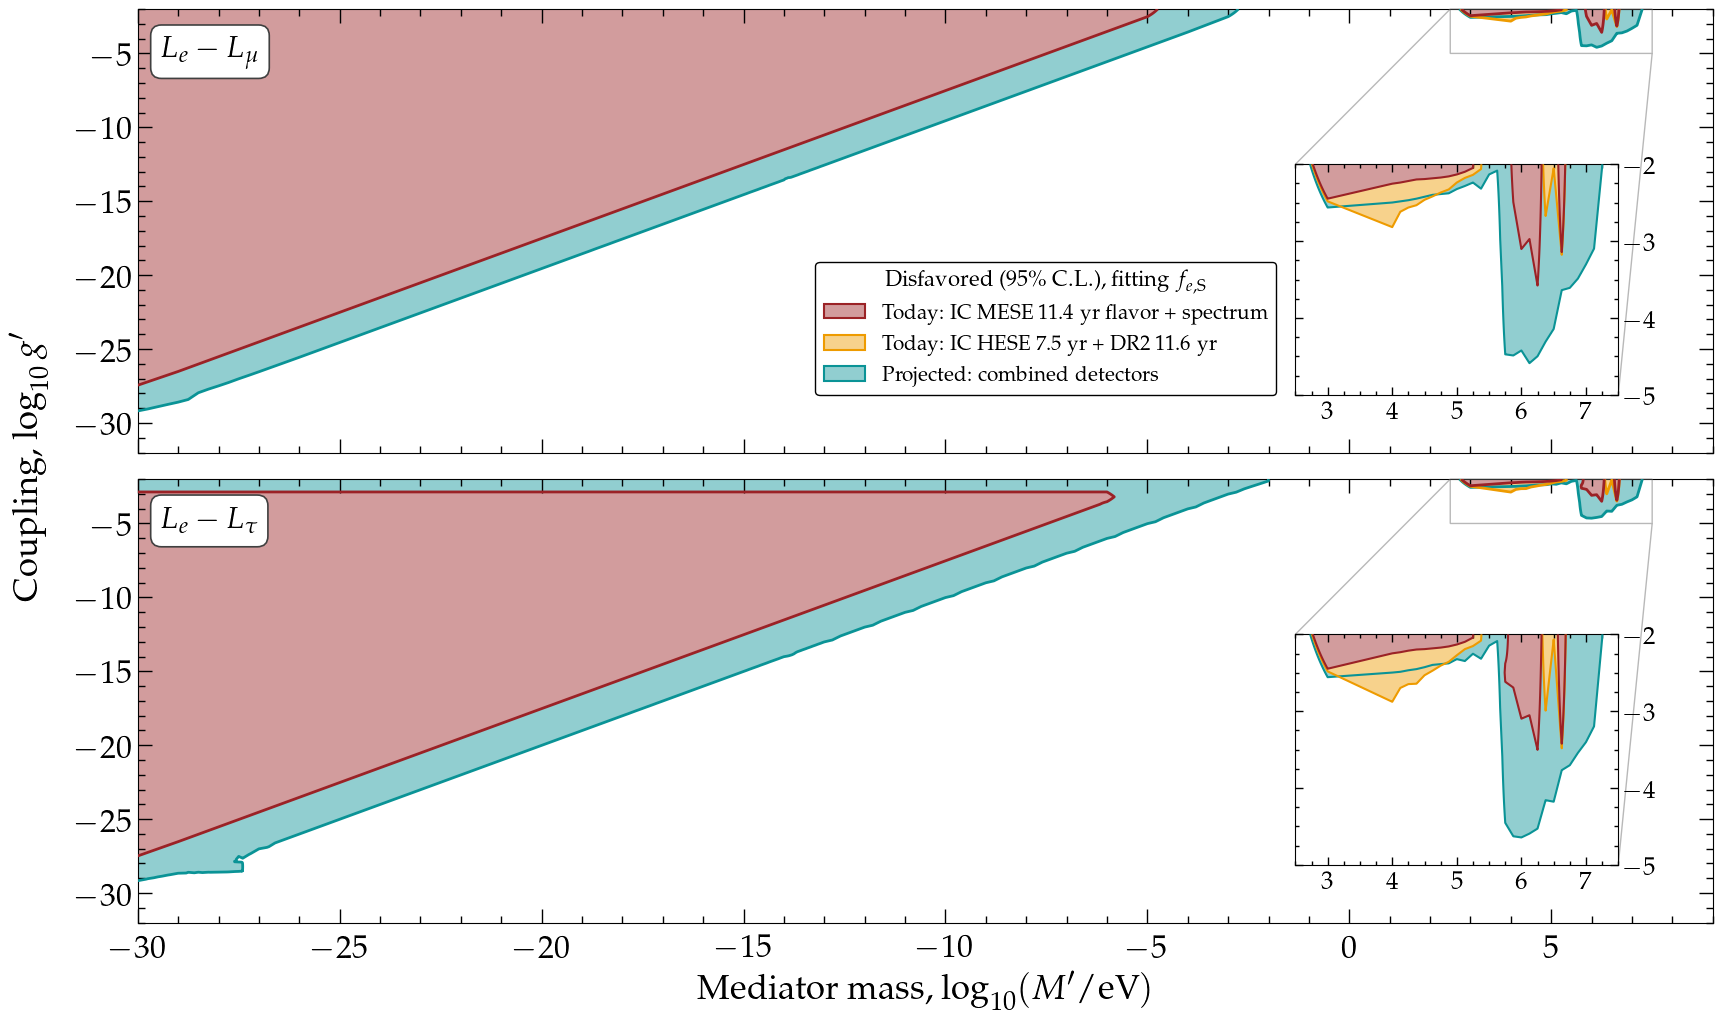

In [3]:
JOINED = [("le_lmu", r"$L_e - L_\mu$"), ("le_ltau", r"$L_e - L_\tau$")]
#: The MeV inset, in axes fractions; the legend's bottom right sits at its bottom left.
MEV_INSET = [0.735, 0.13, 0.205, 0.52]
#: The inset's range: log10 m, log10 g.
MEV_CORNER = ((2.5, 7.5), (-5, -2))


def limits_lmu_ltau(composition):
    suffix = COMPOSITIONS[composition][0]
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(3.5 * PANEL[0], 2 * PANEL[1] + 1.0))
    fig.subplots_adjust(left=0.085, right=0.985, top=0.98, bottom=0.11, hspace=0.06)
    for ax, (model, name) in zip(axes, JOINED):
        regions = []
        for ds, _, color in DRAWN:
            ul, mev = ex.plane(CAMPAIGN, ds, f"{model}_ul{suffix}"), ex.plane(CAMPAIGN, ds, f"{model}_mev{suffix}")
            lx, G, F = ex.merged(ul, mev)
            regions.append((lx, G, F, color))
            ex.draw(ax, lx, G, F, color, tint(color), lw=2.0)
        ins = ax.inset_axes(MEV_INSET)
        for lx, G, F, color in regions:
            ex.draw(ins, lx, G, F, color, tint(color), lw=1.5)
        ins.set_xlim(*MEV_CORNER[0])
        ins.set_ylim(*MEV_CORNER[1])
        ticks(ins, (1, 0.25), (1, 0.25))
        ins.tick_params(labelsize=18, pad=4, length=6, labelleft=False, labelright=True)   # clear of the legend
        ins.tick_params(which="minor", length=3)
        ax.indicate_inset_zoom(ins, edgecolor="0.45")
        ax.set_xlim(-30, 9)
        ax.set_ylim(-32, -2)
        ticks(ax, (5, 1), (5, 1))
        model_label(ax, name)
    axes[1].set_xlabel(X_LABEL)
    fig.text(0.012, 0.545, r"Coupling, $\log_{10} g'$", rotation=90, ha="left", va="center",
             fontsize=plt.rcParams["axes.labelsize"])
    leg = axes[0].legend(handles=handles(), loc="lower right", bbox_to_anchor=(MEV_INSET[0] - 0.012, MEV_INSET[1]),
                         borderaxespad=0.0, fontsize=15, frameon=True, framealpha=1, edgecolor="black",
                         title=legend_title(composition), title_fontsize=16)
    leg.get_frame().set_linewidth(1.0)
    return fig


for composition in COMPOSITIONS:
    fig = limits_lmu_ltau(composition)
    save(fig, f"limits_le_lmu_le_ltau_{composition}")
    plt.show()

**Reading them.** Today's data: IceCube's MESE flavor composition with its 2026 spectrum excludes the
cosmological potential's diagonal ($g' \propto M'$) up to $10^{-4}$ eV; the HESE and DR2 events add, for
$L_e - L_\mu$ with pion-decay sources, the band down to $g' \sim 10^{-28}$. The projection reaches lower couplings at
every mass, and in the MeV corner $g' \sim 10^{-4.5}$ near 1 MeV. With the compositions fitted, the potential's flavor
shift can be absorbed by the sources: the regions shrink to the diagonal.

Two features at the 95% threshold, under study on 2026-10-21 (`tools/check_dips.py`): the thin allowed channel that
splits the projected $L_e - L_\mu$ region with pion-decay sources along $g' \approx 0.03\,M'$ ($\Delta\chi^2$ dips
to 3.3), and the top edge of the MESE region in the fitted $L_e - L_\tau$ panel ($\Delta\chi^2$ falls from 3.9 to 0.5
above $3 \times 10^{-3}$).

## 2. The dark portal's textures at MeV masses

The three textures of the dark portal (the new boson couples through the $e$, $\mu$ or $\tau$ row of the texture),
scanned at MeV masses only. The coupling is the texture's trace. A first version, in the same style as Figure 1:
one panel per texture sharing the coupling axis, the texture's name at the bottom left (the regions fill the top), the legend under the panels.

saved paper/figures/limits_dark_portal_textures_pion.pdf


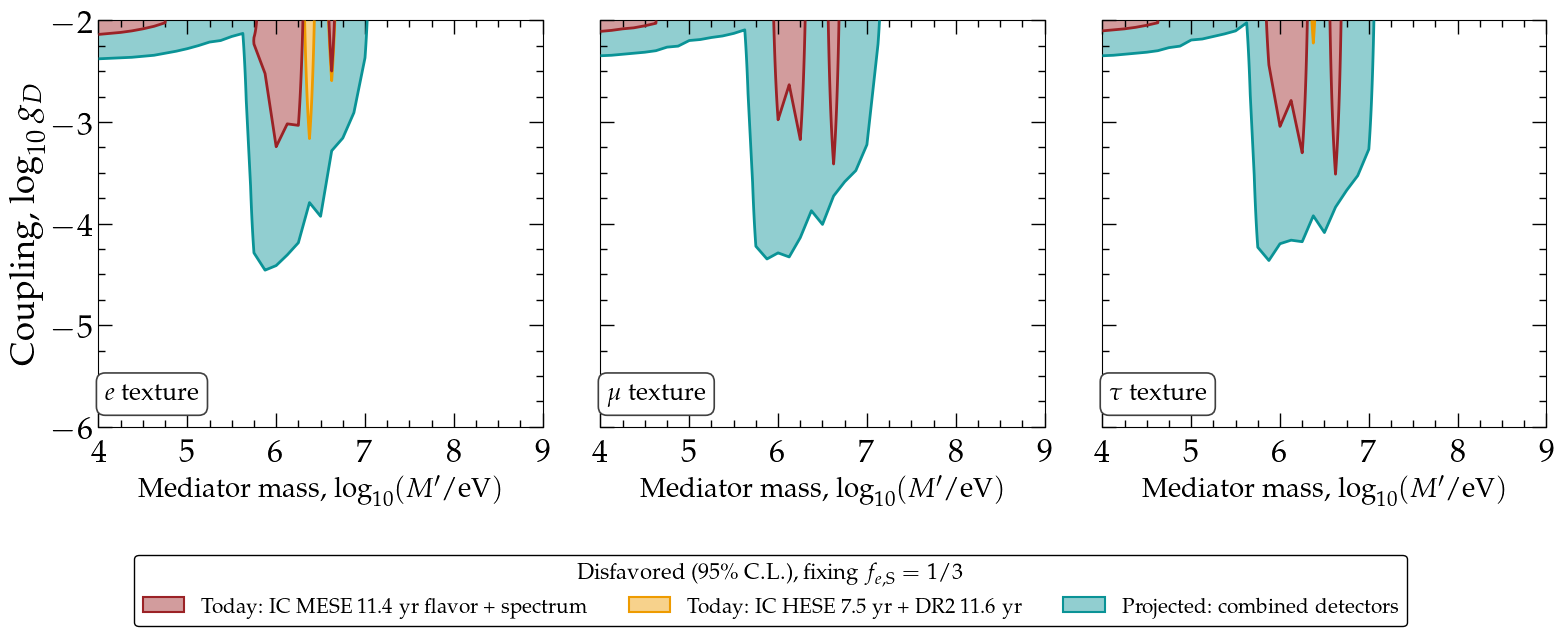

saved paper/figures/limits_dark_portal_textures_fitted.pdf


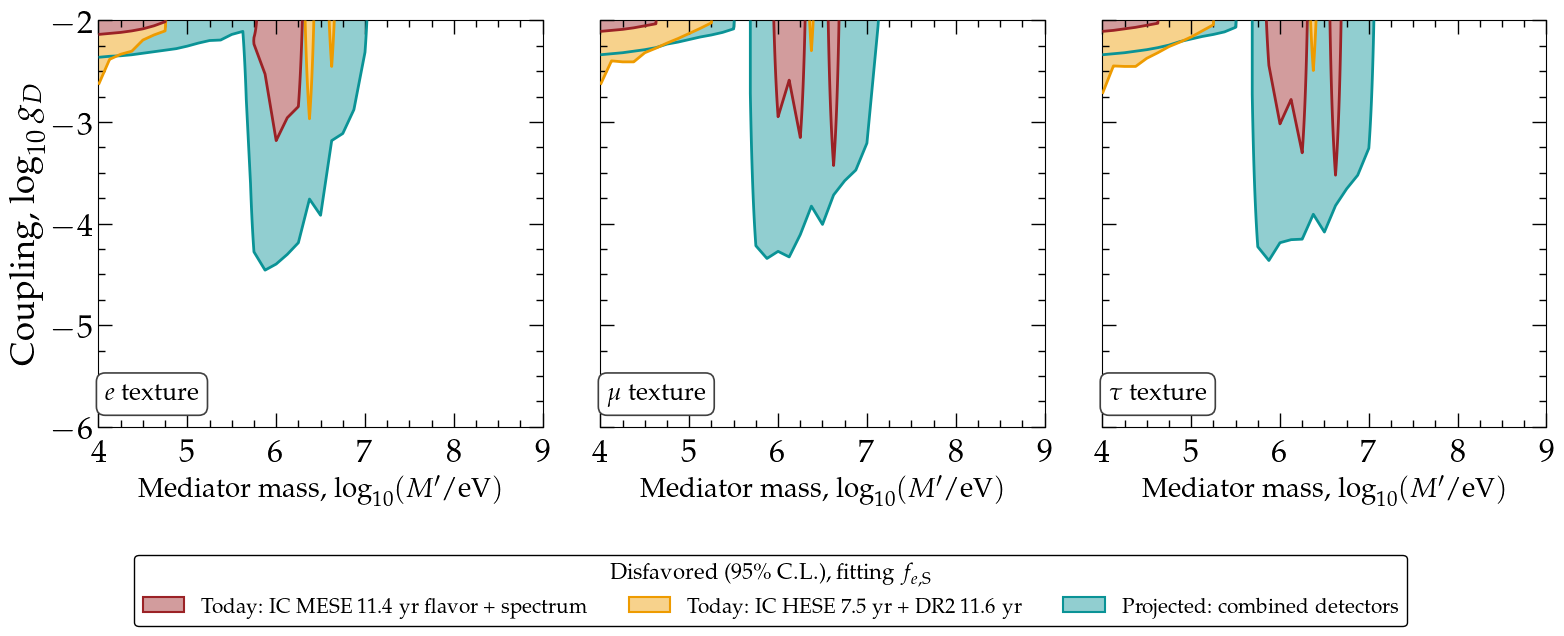

In [4]:
TEXTURES = [("dp_e_mev", r"$e$ texture"), ("dp_mu_mev", r"$\mu$ texture"), ("dp_tau_mev", r"$\tau$ texture")]


def limits_textures(composition):
    suffix = COMPOSITIONS[composition][0]
    fig, axes = plt.subplots(1, 3, sharey=True, figsize=(3 * PANEL[0] + 1.0, PANEL[1] + 1.6))
    fig.subplots_adjust(left=0.08, right=0.985, top=0.97, bottom=0.33, wspace=0.13)
    for ax, (model, name) in zip(axes, TEXTURES):
        for ds, _, color in DRAWN:
            lx, G, F, _, _ = ex.field(ex.plane(CAMPAIGN, ds, model + suffix))
            ex.draw(ax, lx, G, F, color, tint(color), lw=2.0)
        ax.set_xlim(4, 9)
        ax.set_ylim(-6, -2)
        ticks(ax, (1, 0.25), (1, 0.25))
        model_label(ax, name, size=18, where="bottom")
        ax.set_xlabel(X_LABEL, fontsize=20)
    axes[0].set_ylabel(r"Coupling, $\log_{10} g_D$")
    leg = fig.legend(handles=handles(), loc="lower center", ncol=3, fontsize=15, frameon=True, framealpha=1,
                     edgecolor="black", title=legend_title(composition), title_fontsize=16, bbox_to_anchor=(0.5, 0.0))
    leg.get_frame().set_linewidth(1.0)
    return fig


for composition in COMPOSITIONS:
    fig = limits_textures(composition)
    save(fig, f"limits_dark_portal_textures_{composition}")
    plt.show()